| العمود                | المعنى بالعربي                                  | مثال توضيحي                |
| --------------------- | ----------------------------------------------- | -------------------------- |
| `listing_id`          | رقم مميز لكل إعلان سيارة                        | 1001                       |
| `brand`               | ماركة السيارة                                   | Toyota                     |
| `model`               | موديل السيارة                                   | Corolla                    |
| `year`                | سنة تصنيع السيارة                               | 2020                       |
| `mileage_km`          | إجمالي المسافة التي قطعتها السيارة بالكيلومتر   | 85000                      |
| `transmission`        | نوع ناقل الحركة                                 | Automatic / Manual         |
| `fuel_type`           | نوع الوقود المستخدم                             | Petrol / Diesel / Electric |
| `engine_cc`           | سعة المحرك بالسنتيمتر المكعب                    | 1600                       |
| `body_type`           | نوع هيكل السيارة                                | Sedan / SUV / Hatchback    |
| `color`               | لون السيارة                                     | White / Black              |
| `city`                | المدينة التي تُعرض فيها السيارة للبيع           | Cairo / Alexandria         |
| `seller_type`         | نوع البائع                                      | Dealer / Individual        |
| `accident_history`    | هل تعرضت السيارة لحوادث سابقة؟                  | Yes / No                   |
| `previous_owners`     | عدد المالكين السابقين للسيارة                   | 2                          |
| `condition_rating`    | تقييم الحالة العامة للسيارة                     | 1–5 مثلًا                  |
| `photos_count`        | عدد الصور الموجودة في الإعلان                   | 8                          |
| `price_egp`           | سعر السيارة بالجنيه المصري                      | 750000                     |
| `sold_within_30_days` | هل تم بيع السيارة خلال 30 يومًا من نشر الإعلان؟ | 1 = نعم، 0 = لا            |

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier


In [2]:
df = pd.read_csv(r'/content/used_cars_dataset.csv')

In [3]:
df.head()

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,ZS,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,ALEXANDRIA,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,NaN,Fair,8.0,425000,No


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   listing_id           3000 non-null   object 
 1   brand                3000 non-null   object 
 2   model                3000 non-null   object 
 3   year                 3000 non-null   int64  
 4   mileage_km           2822 non-null   float64
 5   transmission         2941 non-null   object 
 6   fuel_type            2940 non-null   object 
 7   engine_cc            2879 non-null   float64
 8   body_type            3000 non-null   object 
 9   color                2851 non-null   object 
 10  city                 2941 non-null   object 
 11  seller_type          2942 non-null   object 
 12  accident_history     3000 non-null   object 
 13  previous_owners      2881 non-null   float64
 14  condition_rating     2851 non-null   object 
 15  photos_count         2907 non-null   f

In [5]:
df.describe()

,year,mileage_km,engine_cc,previous_owners,photos_count,price_egp
count,3000.000000,2.822000e+03,2879.000000,2881.000000,2907.000000,3.000000e+03
mean,2018.174333,1.093424e+05,1654.430358,1.887886,10.543172,7.555841e+05
std,37.275449,2.707599e+05,526.287599,1.008779,8.393483,2.043534e+06
min,0.000000,0.000000e+00,0.000000,1.000000,0.000000,0.000000e+00
25%,2017.000000,5.020000e+04,1500.000000,1.000000,8.000000,3.300000e+05
50%,2020.000000,8.570000e+04,1600.000000,2.000000,10.000000,5.525000e+05
75%,2022.000000,1.339250e+05,1600.000000,2.000000,13.000000,9.400000e+05
max,2050.000000,9.999999e+06,20000.000000,6.000000,300.000000,1.000000e+08


In [6]:
df.describe(include=object)

,listing_id,brand,model,transmission,fuel_type,body_type,color,city,seller_type,accident_history,condition_rating,sold_within_30_days
count,3000,3000,3000,2941,2940,3000,2851,2941,2942,3000,2851,3000
unique,2940,53,14,4,3,2,7,27,4,4,4,2
top,CAR-50004,Hyundai,Corolla,Automatic,Petrol,Sedan,White,Cairo,Individual,No,Good,No
freq,2,489,405,1927,2004,2522,792,841,1958,2396,1435,1635


In [7]:
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique())


listing_id:
['CAR-52762' 'CAR-52678' 'CAR-52822' ... 'CAR-50347' 'CAR-50986'
 'CAR-50666']

brand:
['MG' 'Kia' 'Skoda' 'Fiat' 'Mitsubishi' 'Toyota' 'Hyundai' 'Nissan'
 'Chevrolet' 'Mercedes' 'TOYOTA' 'BMW' 'Renault' 'KIA' 'Mercedes-Benz'
 'CHERY' 'Chery' 'chevrolet' 'nissan' 'hyundai' 'Toyota ' 'NISSAN' 'kia'
 'hyundai ' 'Chery ' 'chery' 'mitsubishi' 'fiat' 'toyota' 'mg'
 'mercedes-benz' 'SKODA' 'Nissan ' 'BMW ' 'HYUNDAI' 'CHEVROLET' 'bmw'
 'skoda' 'MITSUBISHI' 'Hyundai ' 'renault' 'RENAULT' 'MERCEDES-BENZ'
 'Renault ' 'Chevrolet ' 'Skoda ' 'Kia ' 'MG ' 'NISSAN ' 'Fiat ' 'FIAT'
 'Mitsubishi ' 'bmw ']

model:
['ZS' 'Cerato' 'Octavia' 'Tipo' 'Lancer' 'Corolla' 'Elantra' 'Sunny'
 'Tucson' 'Optra' 'C200' '320i' 'Logan' 'Tiggo 7']

year:
[2021 2023 2009 2019 2022 2010 2017 2020 2025 2024 2018 2005 2013 2015
 2016 2012 2011 2008 2014 2006 2031 2007    0 1899 2026 2050 1985 1900
 2035 1970]

mileage_km:
[  64900.      nan  224500. ...   10800. 1100000.  177400.]

transmission:
['Automatic' '

In [8]:
text_columns = df.select_dtypes(include='object').columns

for col in text_columns:
    df[col] = df[col].str.strip().str.title()

In [9]:
df['transmission'] = df['transmission'].replace({
    'Auto': 'Automatic',
    'Mt': 'Manual'
})

In [10]:
df['accident_history'] = df['accident_history'].replace({
    'N': 'No',
    'Y': 'Yes'
})

In [11]:
df[df['engine_cc']==df['engine_cc'].min()]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
787,Car-51241,Nissan,Sunny,2007,261700.0,Manual,Petrol,0.0,Sedan,Silver,Alexandria,Individual,No,2.0,Good,12.0,129000,No
1799,Car-50572,Chevrolet,Optra,2018,131700.0,Automatic,Hybrid,0.0,Sedan,White,Banha,Dealer,No,1.0,Fair,12.0,234000,No


In [12]:
df['engine_cc']=df['engine_cc'].replace({20000:2000,
                                         16000:1600,
                                         12000:1200,
                                         9000:1900,
                                         0:1500,
                                         5:1600,
                                         100:1400})

In [13]:
df['photos_count'] = df['photos_count'].replace({
    300: 30,
    250: 25,
    150: 15,
    99: 9,

})

In [14]:
df.drop(df[df['mileage_km'] == 0].index, inplace=True)

In [15]:
df.drop(df[df['year'] == 0].index, inplace=True)

In [16]:
df.drop(df[df['price_egp'] == 0].index, inplace=True)

In [17]:
df[df['mileage_km']==df['mileage_km'].max()]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
1816,Car-50796,Kia,Cerato,2020,9999999.0,Automatic,Petrol,1600.0,Sedan,White,NaN,Individual,No,2.0,Good,9.0,643000,Yes


In [18]:
df['mileage_km'] = df['mileage_km'].replace({9999999:99999,
                                            8888888:88888,
                                            3000000:300000,
                                             2500000:250000,
                                             1500000:150000,
                                             1200000:120000,
                                             1100000:110000,
                                             999999:99999,
                                             950000:95000})

In [19]:
df['previous_owners'] = df['previous_owners'].round().astype('Int64')
df['photos_count'] = df['photos_count'].round().astype('Int64')

In [20]:
df.duplicated().sum()

np.int64(40)

In [21]:
df.drop_duplicates(inplace=True)

In [22]:
df[df['listing_id'].duplicated(keep=False)].sort_values(
    by='listing_id',
    ascending=True
)

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
2159,Car-50129,Mitsubishi,Lancer,2021,87100.0,Automatic,Petrol,1600.0,Sedan,Black,Giza,Individual,No,2,Excellent,7,329000,Yes
446,Car-50129,Mitsubishi,Lancer,2021,87100.0,Automatic,Petrol,1600.0,Sedan,Black,Giza,Individual,No,2,Excellent,7,339000,Yes
2048,Car-50342,Mercedes-Benz,C200,2017,130400.0,Automatic,Petrol,1600.0,Sedan,Black,Port Said,Individual,No,1,Good,10,1213000,No
2868,Car-50342,Mercedes-Benz,C200,2017,130400.0,Automatic,Petrol,1600.0,Sedan,Black,Port Said,Individual,No,1,Good,10,1177000,No
1169,Car-50457,Mg,Zs,2024,24800.0,Automatic,Hybrid,1500.0,Suv,Black,Alexandria,Dealer,No,2,Fair,12,1080000,Yes
2383,Car-50457,Mg,Zs,2024,24800.0,Automatic,Hybrid,1500.0,Suv,Black,Alexandria,Dealer,No,2,Fair,12,1113000,Yes
2873,Car-50518,Mercedes-Benz,C200,2020,85300.0,Automatic,Petrol,1600.0,Sedan,Blue,Giza,Dealer,No,1,Excellent,14,1637000,No
2777,Car-50518,Mercedes-Benz,C200,2020,85300.0,Automatic,Petrol,1600.0,Sedan,Blue,Giza,Dealer,No,1,Excellent,14,1688000,No
2432,Car-50519,Hyundai,Elantra,2019,90900.0,Automatic,Diesel,1600.0,Sedan,Grey,Cairo,Individual,No,5,Good,8,540000,No
1863,Car-50519,Hyundai,Elantra,2019,90900.0,Automatic,Diesel,1600.0,Sedan,Grey,Cairo,Individual,No,5,Good,8,557000,No


In [23]:
df.drop_duplicates(subset='listing_id', keep='first', inplace=True)

In [24]:
df.isnull().sum()

,0
listing_id,0
brand,0
model,0
year,0
mileage_km,175
transmission,58
fuel_type,58
engine_cc,117
body_type,0
color,146


In [25]:
df[df['mileage_km'].isnull()]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
1,Car-52678,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1,Good,12,1012000,No
9,Car-51630,Mg,Zs,2017,NaN,Automatic,Petrol,1500.0,Suv,White,Mansoura,Individual,No,3,Good,8,416000,No
23,Car-52348,Hyundai,Elantra,2005,NaN,Automatic,Petrol,2000.0,Sedan,Blue,Alexandria,Individual,No,3,Fair,3,157000,No
63,Car-51627,Toyota,Corolla,2023,NaN,Automatic,Hybrid,1800.0,Sedan,Black,Alexandria,Individual,No,1,Good,13,1333000,Yes
79,Car-51252,Nissan,Sunny,2012,NaN,Manual,Petrol,1500.0,Sedan,Black,Cairo,Dealer,Yes,1,Good,10,146000,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2947,Car-50676,Hyundai,Elantra,2018,NaN,Automatic,Petrol,2000.0,Sedan,Red,Alexandria,Dealer,No,3,Fair,14,530000,No
2957,Car-52067,Nissan,Sunny,2022,NaN,Manual,Petrol,1500.0,Sedan,White,Mansoura,Dealer,No,<NA>,Poor,<NA>,483000,No
2960,Car-50132,Hyundai,Elantra,2014,NaN,Automatic,Petrol,2000.0,Sedan,Silver,Tanta,Individual,No,1,Excellent,10,382000,No
2970,Car-50847,Kia,Cerato,2023,NaN,Automatic,Hybrid,1600.0,Sedan,White,Alexandria,Individual,No,1,Good,7,1063000,No


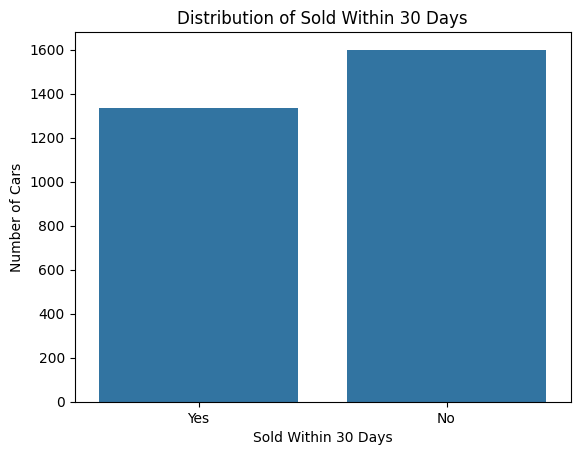

In [26]:
sns.countplot(data=df, x='sold_within_30_days')

plt.title('Distribution of Sold Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Number of Cars')
plt.show()

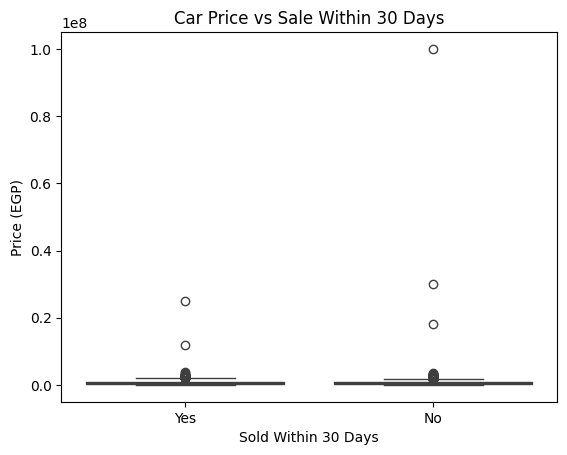

In [27]:
sns.boxplot(
    data=df,
    x='sold_within_30_days',
    y='price_egp'
)

plt.title('Car Price vs Sale Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Price (EGP)')
plt.show()

In [28]:
df.nlargest(20, 'price_egp')[
    ['brand', 'model', 'year', 'price_egp']
]

,brand,model,year,price_egp
178,Nissan,Sunny,2008,99999999
2552,Chery,Tiggo 7,2019,30000000
1182,Skoda,Octavia,2013,25000000
358,Skoda,Octavia,2015,18000000
499,Hyundai,Elantra,2022,12000000
1482,Mercedes-Benz,C200,2026,3818000
1653,Mercedes-Benz,C200,2023,3585000
1867,Mercedes-Benz,C200,2025,3455000
2023,Mercedes-Benz,C200,2024,3366000
1620,Mercedes-Benz,C200,2025,3332000


In [29]:
df.drop(index=[178,2552,1182,358], inplace=True)
df.reset_index(drop=True, inplace=True)
df['price_egp'].replace(12000000,1200000, inplace=True)

/tmp/ipykernel_27104/1846346365.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['price_egp'].replace(12000000,1200000, inplace=True)


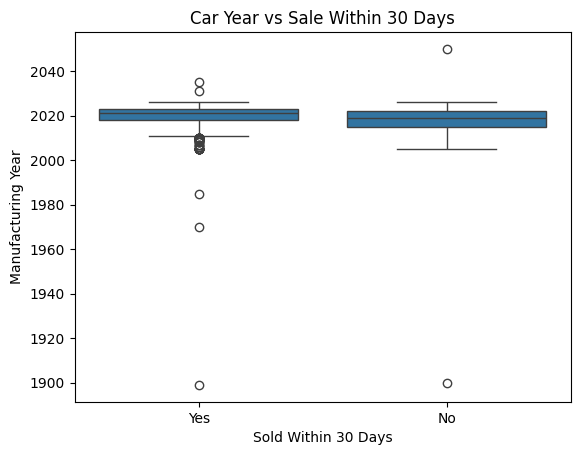

In [30]:
sns.boxplot(
    data=df,
    x='sold_within_30_days',
    y='year'
)

plt.title('Car Year vs Sale Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Manufacturing Year')
plt.show()

In [31]:
df = df[(df['year'] > 1990) & (df['year'] < 2027)]

In [32]:
df[(df['year'] < 2010) & (df['sold_within_30_days'] == 'Yes')]

,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
65,Car-50617,Mg,Zs,2006,274700.0,Automatic,Diesel,1500.0,Suv,White,Alexandria,Individual,No,4,NaN,10,149000,Yes
222,Car-52235,Toyota,Corolla,2005,237500.0,Automatic,Petrol,1600.0,Sedan,Black,Giza,Dealer,No,3,Good,12,230000,Yes
252,Car-50689,Hyundai,Elantra,2007,306200.0,NaN,Petrol,1600.0,Sedan,NaN,Cairo,Dealer,No,1,Good,9,211000,Yes
270,Car-50428,Hyundai,Elantra,2006,299700.0,Automatic,Petrol,2000.0,Sedan,NaN,Giza,Dealer,No,4,Fair,12,196000,Yes
295,Car-52030,Toyota,Corolla,2007,244000.0,Automatic,Petrol,1600.0,Sedan,White,Mansoura,Individual,No,1,Good,8,199000,Yes
375,Car-50389,Chery,Tiggo 7,2005,312300.0,Automatic,Petrol,1500.0,Suv,Black,Assiut,Individual,No,4,Fair,4,193000,Yes
434,Car-51765,Fiat,Tipo,2008,238000.0,Manual,Petrol,1600.0,Sedan,Grey,Giza,Individual,No,3,NaN,11,87000,Yes
500,Car-50979,Toyota,Corolla,2009,200800.0,Automatic,Petrol,1800.0,Sedan,Black,NaN,Dealer,No,1,Excellent,11,226000,Yes
676,Car-51405,Hyundai,Elantra,2009,242800.0,Automatic,Petrol,2000.0,Sedan,Black,Assiut,Individual,No,2,Good,8,137000,Yes
748,Car-52510,Chery,Tiggo 7,2005,249900.0,Automatic,Diesel,1600.0,Suv,White,Giza,Individual,No,3,Fair,11,174000,Yes


In [33]:
df.shape

(2921, 18)

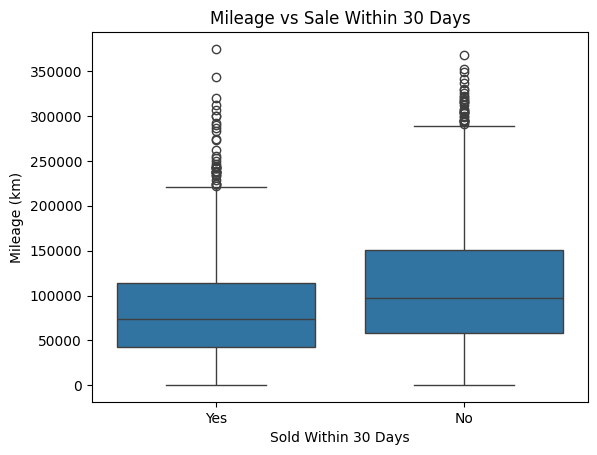

In [34]:
sns.boxplot(
    data=df,
    x='sold_within_30_days',
    y='mileage_km'
)

plt.title('Mileage vs Sale Within 30 Days')
plt.xlabel('Sold Within 30 Days')
plt.ylabel('Mileage (km)')
plt.show()

In [35]:
df.nlargest(20, 'mileage_km')[
    ['brand', 'model', 'year', 'price_egp','mileage_km']
]

,brand,model,year,price_egp,mileage_km
1985,Hyundai,Elantra,2005,162000,374600.0
2314,Chery,Tiggo 7,2005,220000,368300.0
189,Toyota,Corolla,2005,251000,352300.0
1357,Kia,Cerato,2005,167000,349300.0
1409,Mercedes-Benz,C200,2005,363000,343100.0
1673,Bmw,320I,2005,333000,341300.0
216,Skoda,Octavia,2005,204000,336200.0
1291,Hyundai,Tucson,2005,232000,329500.0
1456,Mercedes-Benz,C200,2005,539000,329100.0
220,Mg,Zs,2005,212000,325600.0


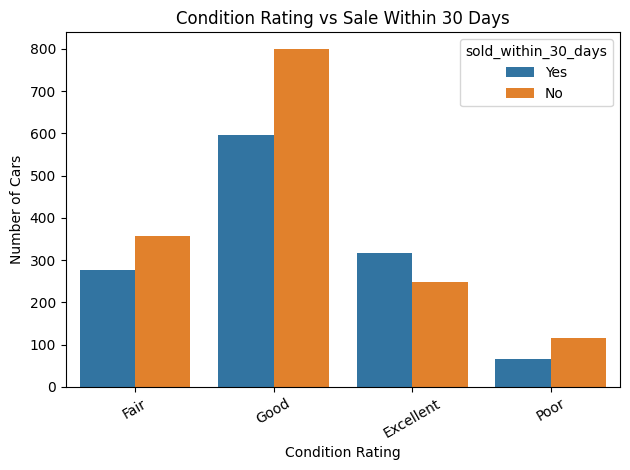

In [36]:
sns.countplot(
    data=df,
    x='condition_rating',
    hue='sold_within_30_days'
)

plt.title('Condition Rating vs Sale Within 30 Days')
plt.xlabel('Condition Rating')
plt.ylabel('Number of Cars')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

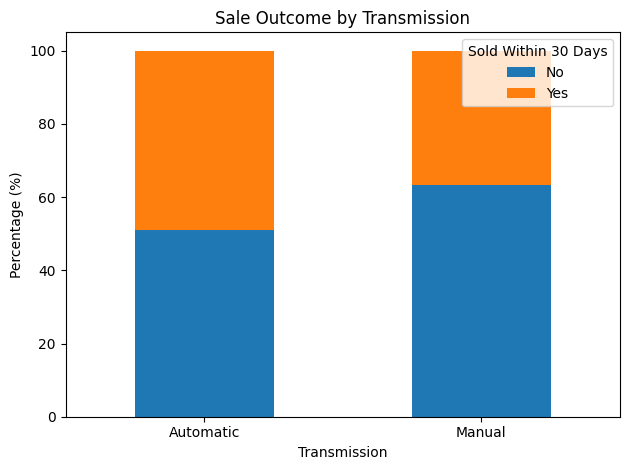

In [37]:
sale_rate = pd.crosstab(
    df['transmission'],
    df['sold_within_30_days'],
    normalize='index'
) * 100

sale_rate.plot(kind='bar', stacked=True)

plt.title('Sale Outcome by Transmission')
plt.xlabel('Transmission')
plt.ylabel('Percentage (%)')
plt.legend(title='Sold Within 30 Days')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

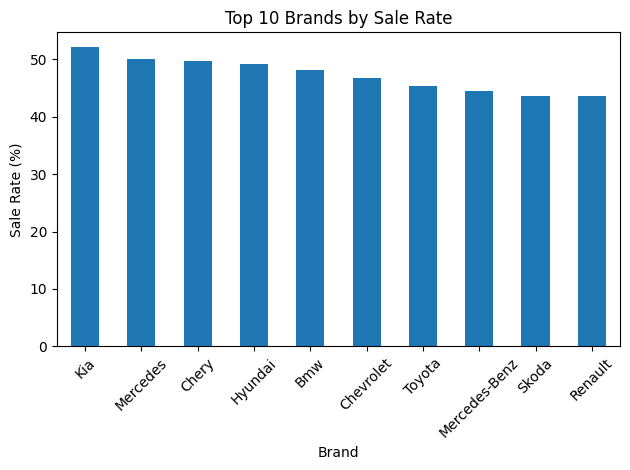

In [38]:
brand_sale_rate = (
    df.groupby('brand')['sold_within_30_days']
      .apply(lambda x: x.eq('Yes').mean() * 100)
      .sort_values(ascending=False)
      .head(10)
)

brand_sale_rate.plot(kind='bar')

plt.title('Top 10 Brands by Sale Rate')
plt.xlabel('Brand')
plt.ylabel('Sale Rate (%)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

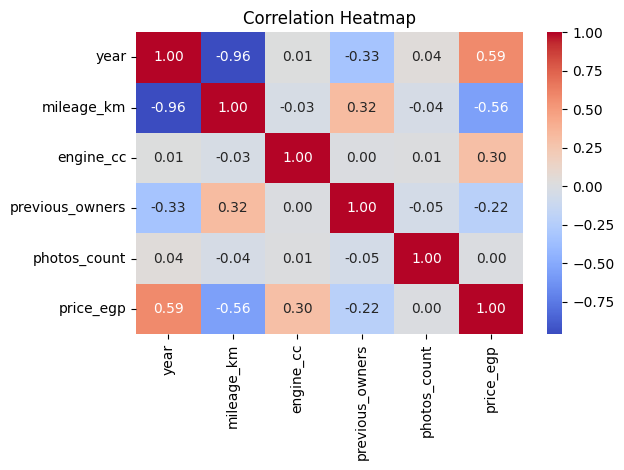

In [39]:
numeric_cols = [
    'year',
    'mileage_km',
    'engine_cc',
    'previous_owners',
    'photos_count',
    'price_egp'
]

corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

In [40]:
X = df.drop(columns=['listing_id', 'sold_within_30_days'])
y = df['sold_within_30_days']
X_test, X_train, y_test, y_train = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)


In [41]:

num_cols = X_train.select_dtypes(include='number').columns
cat_cols = X_train.select_dtypes(include='object').columns

# Numeric columns: Median
num_imputer = SimpleImputer(strategy='median')

X_train[num_cols] = num_imputer.fit_transform(X_train[num_cols])
X_test[num_cols] = num_imputer.transform(X_test[num_cols])

# Categorical columns: Most frequent
cat_imputer = SimpleImputer(strategy='most_frequent')

X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

In [42]:
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [43]:
y_train = y_train.map({'No': 0, 'Yes': 1})
y_test = y_test.map({'No': 0, 'Yes': 1})

In [44]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [45]:
models = {
    "LR": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(),
    "DT": DecisionTreeClassifier(random_state=42)
}

results = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train)

    # Prediction
    y_pred = model.predict(X_test)

    # Evaluation
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,Model,Accuracy,Precision,Recall,F1-Score
0,LR,0.6336,0.6314,0.6336,0.6301
1,Naive Bayes,0.5672,0.5784,0.5672,0.5667
2,DT,0.5505,0.5489,0.5505,0.5495
3,KNN,0.5351,0.5345,0.5351,0.5348
4,SVM,0.5497,0.5461,0.5497,0.4277


In [46]:
models_params = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=2000, random_state=42),
        'params': {
            'C': [0.1, 1, 10],
            'solver': ['lbfgs'],
            'class_weight': [None, 'balanced']
        },
        'scaled': True
    },

    'KNN': {
        'model': KNeighborsClassifier(),
        'params': {
            'n_neighbors': [3, 5, 7, 9],
            'weights': ['uniform', 'distance'],
            'p': [1, 2]
        },
        'scaled': True
    },

    'Naive Bayes': {
        'model': GaussianNB(),
        'params': {
            'var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6]
        },
        'scaled': False
    },

    'SVM': {
        'model': SVC(),
        'params': {
            'C': [0.1, 1, 10],
            'kernel': ['linear', 'rbf'],
            'class_weight': [None, 'balanced']
        },
        'scaled': True
    },

    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'params': {
            'criterion': ['gini', 'entropy'],
            'max_depth': [None, 5, 10, 15],
            'min_samples_split': [2, 10],
            'min_samples_leaf': [1, 5],
            'class_weight': [None, 'balanced']
        },
        'scaled': False
    },

    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'params': {
            'n_estimators': [100, 200],
            'max_depth': [None, 10, 20],
            'min_samples_split': [2, 10],
            'min_samples_leaf': [1, 5],
            'class_weight': [None, 'balanced']
        },
        'scaled': False
    }
}

In [47]:


grid_results = []
best_models = {}

for name, config in models_params.items():

    if config['scaled']:
        Xtr = X_train_scaled
    else:
        Xtr = X_train

    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['params'],
        scoring='f1',
        cv=5,
        n_jobs=-1,
        refit=True
    )

    grid.fit(Xtr, y_train)

    best_models[name] = grid.best_estimator_

    grid_results.append({
        'Model': name,
        'Best Parameters': grid.best_params_,
        'Best CV F1': grid.best_score_
    })

    print(f'{name} completed')
    print('Best Parameters:', grid.best_params_)
    print('Best CV F1:', round(grid.best_score_, 4))
    print('-' * 50)

grid_results_df = pd.DataFrame(grid_results)
grid_results_df.sort_values(
    'Best CV F1', ascending=False
)

Logistic Regression completed
Best Parameters: {'C': 10, 'class_weight': 'balanced', 'solver': 'lbfgs'}
Best CV F1: 0.6405
--------------------------------------------------
KNN completed
Best Parameters: {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}
Best CV F1: 0.5201
--------------------------------------------------
Naive Bayes completed
Best Parameters: {'var_smoothing': 1e-06}
Best CV F1: 0.5501
--------------------------------------------------
SVM completed
Best Parameters: {'C': 1, 'class_weight': 'balanced', 'kernel': 'linear'}
Best CV F1: 0.6394
--------------------------------------------------
Decision Tree completed
Best Parameters: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 10}
Best CV F1: 0.5464
--------------------------------------------------
Random Forest completed
Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2, 'n_estimators': 200}
Best

,Model,Best Parameters,Best CV F1
0,Logistic Regression,"{'C': 10, 'class_weight': 'balanced', 'solver'...",0.640458
3,SVM,"{'C': 1, 'class_weight': 'balanced', 'kernel':...",0.639449
5,Random Forest,"{'class_weight': 'balanced', 'max_depth': 10, ...",0.585939
2,Naive Bayes,{'var_smoothing': 1e-06},0.550050
4,Decision Tree,"{'class_weight': 'balanced', 'criterion': 'gin...",0.546442
1,KNN,"{'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}",0.520123


In [48]:


best_model_name = max(
    grid_results,
    key=lambda x: x['Best CV F1']
)['Model']

best_model = best_models[best_model_name]

if models_params[best_model_name]['scaled']:
    Xte = X_test_scaled
else:
    Xte = X_test

y_pred_best = best_model.predict(Xte)

print('Best Model:', best_model_name)
print('Test Accuracy:', accuracy_score(y_test, y_pred_best))
print('Test F1-score:', f1_score(y_test, y_pred_best))

print('\nClassification Report:')
print(classification_report(
    y_test, y_pred_best, zero_division=0
))

print('\nConfusion Matrix:')
print(confusion_matrix(y_test, y_pred_best))


Best Model: Logistic Regression
Test Accuracy: 0.6305650684931506
Test F1-score: 0.5961628451099672

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.66      0.66      1275
           1       0.59      0.60      0.60      1061

    accuracy                           0.63      2336
   macro avg       0.63      0.63      0.63      2336
weighted avg       0.63      0.63      0.63      2336


Confusion Matrix:
[[836 439]
 [424 637]]


In [49]:

import gradio as gr

def predict(
    brand, model, year, mileage_km,
    transmission, fuel_type, engine_cc,
    body_type, color, city, seller_type,
    accident_history, previous_owners,
    condition_rating, photos_count
):
    X_new = pd.DataFrame([{
        'brand': brand,
        'model': model,
        'year': year,
        'mileage_km': mileage_km,
        'transmission': transmission,
        'fuel_type': fuel_type,
        'engine_cc': engine_cc,
        'body_type': body_type,
        'color': color,
        'city': city,
        'seller_type': seller_type,
        'accident_history': accident_history,
        'previous_owners': previous_owners,
        'condition_rating': condition_rating,
        'photos_count': photos_count
    }], columns=input_columns)

    # Clean text values
    for col in categorical_cols:
        X_new[col] = X_new[col].astype('object').str.strip()

    # Impute missing values
    X_new[numeric_cols] = num_imputer.transform(
        X_new[numeric_cols]
    )
    X_new[categorical_cols] = cat_imputer.transform(
        X_new[categorical_cols]
    )

    # One-hot encoding and align with training columns
    X_new = pd.get_dummies(X_new, dtype=int)
    X_new = X_new.reindex(
        columns=feature_columns,
        fill_value=0
    )

    # Apply scaling only for models that require it
    if best_model_name in [
        'Logistic Regression', 'KNN', 'SVM'
    ]:
        X_input = scaler.transform(X_new)
    else:
        X_input = X_new

    prediction = best_model.predict(X_input)[0]

    return (
        "Likely to sell within 30 days"
        if prediction == 1
        else "Not predicted to sell within 30 days"
    )


demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Dropdown(
            choices=sorted(df['brand'].dropna().unique().tolist()),
            label="Brand"
        ),
        gr.Dropdown(
            choices=sorted(df['model'].dropna().unique().tolist()),
            label="Model"
        ),
        gr.Number(label="Year", precision=0),
        gr.Number(label="Mileage (km)"),
        gr.Dropdown(
            choices=sorted(df['transmission'].dropna().unique().tolist()),
            label="Transmission"
        ),
        gr.Dropdown(
            choices=sorted(df['fuel_type'].dropna().unique().tolist()),
            label="Fuel Type"
        ),
        gr.Number(label="Engine CC"),
        gr.Dropdown(
            choices=sorted(df['body_type'].dropna().unique().tolist()),
            label="Body Type"
        ),
        gr.Dropdown(
            choices=sorted(df['color'].dropna().unique().tolist()),
            label="Color"
        ),
        gr.Dropdown(
            choices=sorted(df['city'].dropna().unique().tolist()),
            label="City"
        ),
        gr.Dropdown(
            choices=sorted(df['seller_type'].dropna().unique().tolist()),
            label="Seller Type"
        ),
        gr.Radio(
            choices=["Yes", "No"],
            label="Accident History"
        ),
        gr.Number(label="Previous Owners", precision=0),
        gr.Dropdown(
            choices=sorted(
                df['condition_rating'].dropna().unique().tolist()
            ),
            label="Condition Rating"
        ),
        gr.Number(label="Photos Count", precision=0)
    ],
    outputs=gr.Textbox(label="Prediction"),
    title="Used Car Sale Prediction",
    description="Predict whether a car will sell within 30 days."
)

demo.launch()


It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://980d69059459aa3a72.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
